# Panelowe modele liczebności — medale olimpijskie**Dane:** wyniki olimpijskie (zbiór *josephcheng123456*, `data/raw/`) + World Bank WDI(PKB per capita i populacja, `data/raw/wdi_worldbank.csv`).**Panel:** kraj (NOC) × letnie igrzyska (edition).**Zmienna objaśniana:** `medals` — liczba medali, po deduplikacji medali drużynowych.Logika obliczeniowa jest w `src/`; notebook ją wywołuje i opisuje. Kolejność rozdziałówodpowiada wykładowi *„Panelowe modele liczebności"*:1. Wczytanie danych olimpijskich i WDI.2. Budowa panelu kraj × igrzyska (dedup drużynowych medali, merge z WDI).3. Przekrojowy model Poissona i ocena nadmiernej dyspersji.4. Modele panelowe: pooled / PA (GEE) / FE Poisson, ujemny dwumianowy, CRE-Mundlak, ZIP.5. Interpretacja (IRR, elastyczności), porównanie modeli, SE klastrowane po kraju.6. Tabele publikacyjne i wykresy zapisywane do `reports/`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Korzen projektu szukany w gore po src/data_load.py - katalog roboczy notebooka
# bywa ustawiany roznie przez edytory oparte na VS Code.
_here = Path.cwd().resolve()
while not (_here / 'src' / 'data_load.py').is_file():
    if _here == _here.parent:
        raise RuntimeError(f'Nie znaleziono korzenia projektu startujac z {Path.cwd()}.')
    _here = _here.parent
sys.path.insert(0, str(_here))

from src import data_load, inference, model, pre_processing, visualisation as viz

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
np.random.seed(42)
viz.setup_style()

print('Korzen projektu:', data_load.PROJECT_ROOT.name)
print('Pliki surowe:', sorted(p.name for p in data_load.RAW.glob('*.csv')))

Korzen projektu: panel-medale-olimpijskie
Pliki surowe: ['Olympic_Athlete_Bio.csv', 'Olympic_Athlete_Event_Results.csv', 'Olympic_Games_Medal_Tally.csv', 'Olympic_Results.csv', 'Olympics_Country.csv', 'Olympics_Games.csv', 'wdi_worldbank.csv']


## 1. Wczytanie danych- `Olympic_Athlete_Event_Results.csv` — wyniki na poziomie zawodnik × konkurencja  (`medal`, `isTeamSport`).- `Olympics_Games.csv` — meta igrzysk (`edition_id`, `year`, gospodarz `country_noc`).Ograniczenie do **letnich** igrzysk daje spójny panel co 4 lata; WDI to dane roczne.

In [2]:
ev = data_load.load_event_results()
summer = data_load.load_summer_games()

print('Wyniki:', ev.shape)
print('Letnie edycje:', summer['edition_id'].nunique(),
      '| lata:', summer['year'].min(), '-', summer['year'].max())
ev[['edition', 'edition_id', 'country_noc', 'event', 'medal', 'isTeamSport']].head()

Wyniki: (316834, 11)
Letnie edycje: 35 | lata: 1896 - 2032


,edition,edition_id,country_noc,event,medal,isTeamSport
0,1908 Summer Olympics,5,ANZ,"100 metres, Men",NaN,False
1,1908 Summer Olympics,5,ANZ,"400 metres, Men",NaN,False
2,1908 Summer Olympics,5,ANZ,"800 metres, Men",NaN,False
3,1908 Summer Olympics,5,ANZ,"800 metres, Men",NaN,False
4,1908 Summer Olympics,5,ANZ,"800 metres, Men",NaN,False


## 2. Budowa panelu kraj × igrzyska**Medale (Y):** deduplikacja medali drużynowych — jeden medal = unikalna krotka`(edition_id, country_noc, event, medal)`. Drużyna jedenastu piłkarzy to jedno złoto,nie jedenaście.**Zera:** panel budujemy z listy **uczestnictw**, nie z listy medali. Kraj, którywystartował i nie zdobył medalu, ma `medals = 0` — model liczebności wymaga tych zer,a lista medali by je pominęła.**Opóźnienie:** `medals_lag` to medale kraju na jego poprzednich letnich igrzyskach,liczone przesunięciem **wewnątrz kraju**, więc pierwsza obserwacja każdego kraju ma brak.

In [3]:
panel = pre_processing.build_panel(ev, summer)

print('Panel (przed WDI):', panel.shape)
print('Udzial zer:', round((panel['medals'] == 0).mean(), 3))
print('Braki w medals_lag:', panel['medals_lag'].isna().sum(), '/', len(panel))
panel.sort_values('medals', ascending=False).head()

Panel (przed WDI): (2983, 7)
Udzial zer: 0.55
Braki w medals_lag: 229 / 2983


,edition_id,country_noc,medals,year,host_noc,host,medals_lag
2840,3,USA,241,1904,USA,1,51.0000
2814,20,URS,189,1980,URS,1,122.0000
2856,21,USA,170,1984,USA,1,93.0000
977,5,GBR,134,1908,GBR,1,2.0000
2815,22,URS,130,1988,KOR,0,189.0000


## 3. World Bank WDIKody **NOC** różnią się od **ISO3** Banku Światowego (GER→DEU, NED→NLD, SUI→CHE,RSA→ZAF i kilkadziesiąt dalszych — słownik w `src/data_load.py`). Pobierane serie:- `NY.GDP.PCAP.KD` — PKB per capita (stałe USD 2015),- `SP.POP.TOTL` — populacja.Domyślnie czytamy zapisaną kopię z `data/raw/wdi_worldbank.csv`. Odświeżenie z APIwymaga pakietu `wbgapi` i wywołania `load_wdi(..., refresh=True)`; nieudane pobraniejest wtedy zgłaszane wprost, a nie maskowane cichym odczytem pliku.

In [4]:
wdi = data_load.load_wdi()
print('WDI:', wdi.shape, '| kolumny:', list(wdi.columns))
wdi.head()

WDI: (11895, 4) | kolumny: ['iso3', 'year', 'gdp_pc', 'pop']


,iso3,year,gdp_pc,pop
0,ABW,1960,NaN,"54,922.0000"
1,ABW,1961,NaN,"55,578.0000"
2,ABW,1962,NaN,"56,320.0000"
3,ABW,1963,NaN,"57,002.0000"
4,ABW,1964,NaN,"57,619.0000"


In [5]:
df = pre_processing.merge_wdi(panel, wdi)
model_df = pre_processing.to_model_frame(df, save=True)

opis = pre_processing.describe_panel(model_df)
print(f"Obserwacji: {len(df)} -> {opis['N']} po usunieciu brakow")
print(f"Krajow: {opis['krajow']} | edycji: {opis['edycji']} | "
      f"lata: {opis['rok_min']}-{opis['rok_max']}")
print(f"Udzial zer: {opis['udzial_zer']:.1%} | "
      f"srednia: {opis['srednia']:.2f} | wariancja: {opis['wariancja']:.2f}")
model_df[['country_noc', 'year', 'medals', 'medals_lag', 'log_pop', 'log_gdp_pc', 'host']].head()

Zapisano panel analityczny: panel_analityczny.csv (2072 obserwacji)
Obserwacji: 2983 -> 2072 po usunieciu brakow
Krajow: 193 | edycji: 16 | lata: 1960-2020
Udzial zer: 57.4% | srednia: 4.69 | wariancja: 172.25


,country_noc,year,medals,medals_lag,log_pop,log_gdp_pc,host
0,AFG,2004,0,0.0000,16.9751,5.8249,0
1,AFG,2008,1,0.0000,17.0920,6.0346,0
2,AFG,2012,1,1.0000,17.2352,6.3438,0
3,AFG,2016,0,1.0000,17.3623,6.3348,0
4,AFG,2020,0,0.0000,17.4808,6.2688,0


## 3a. Analiza eksploracyjna — rozkład i zależności- **Rozkład medali** — silnie skośny, z dużym udziałem zer; zapowiada nadmierną  dyspersję i nadmiar zer.- **Scatter** — dodatnie zależności `log(1+medale)` od `log PKB pc` i `log populacji`.Wykresy zapisują się do `reports/figures/` i są osadzone w README.

Zapisano wykres: rozklad_medali.png


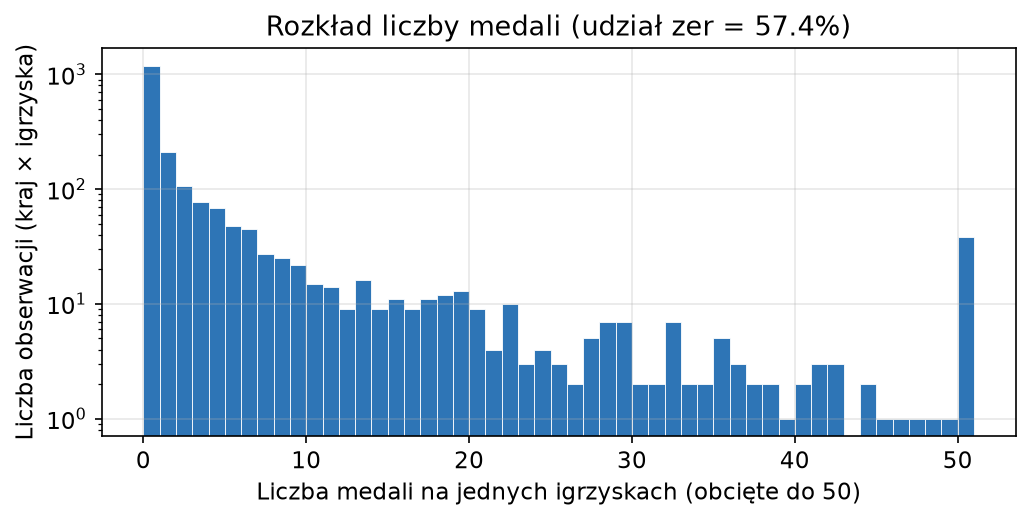

In [6]:
viz.plot_medal_distribution(model_df);

Zapisano wykres: medale_pkb_populacja.png


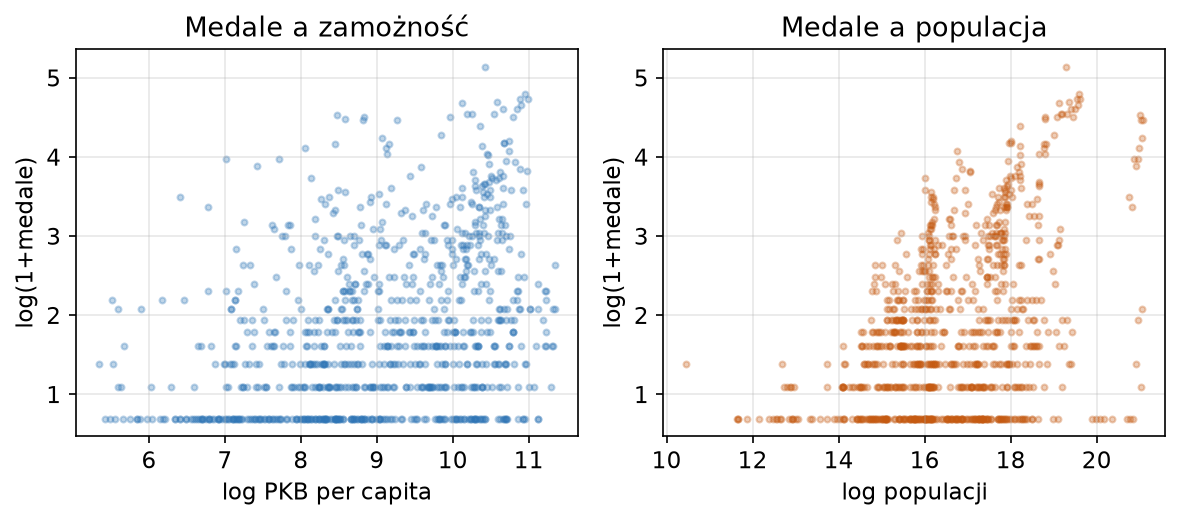

In [7]:
viz.plot_medals_vs_covariates(model_df);

## 4. Modele panelowe liczebnościMapowanie modeli z wykładu na nasz panel:| Sekcja | Model | Odpowiednik w Stacie ||---|---|---|| 4a | Pooled Poisson + ocena dyspersji | `poisson` || 4b | **Pooled Poisson + odporna macierz (klaster)** — rekomendacja Wooldridge'a | `poisson, vce(cluster)` || 4c | Ujemny dwumianowy (NegBin2) | `nbreg` || 4d | **FE-Poisson** (efekty stałe kraju + igrzysk) — najbezpieczniejszy wybór | `xtpoisson, fe` || 4e | PA Poisson (GEE, population-averaged) | `xtpoisson, pa` || 4f | CRE / Mundlak Poisson (+ test ≈ Hausman FE vs RE) | CRE Poisson || 4g | Zero-inflated Poisson | `zip` |Wszystkie siedem specyfikacji szacujemy **jednym wywołaniem** `model.fit_all`, a kolejnekomórki czytają z gotowego słownika. Na tym panelu całość liczy się poniżej dwóch sekund,więc nie ma powodu dzielić przebiegu — a przy jednym dopasowaniu nie da się przypadkiemporównać dwóch różnych przebiegów.

In [8]:
fits = model.fit_all(model_df)
print('Oszacowane:', [k for k in fits if k not in ('cre_df', 'mundlak_bars')])

Oszacowane: ['pooled', 'pooled_cluster', 'negbin', 'fe', 'pa', 'cre', 'zip']


### 4a. Pooled Poisson + ocena nadmiernej dyspersjiW Poissonie zakładamy `Var(Y) = E(Y)`. **Pearson χ²/df** istotnie powyżej 1 oznacza**nadmierną dyspersję**: oszacowania `β` pozostają zgodne, ale błędy standardowe MNWsą błędne.

In [9]:
pois = fits['pooled']
print(pois.summary())

chi2_p, df_p, disp = inference.dispersion_parts(pois)
print(f'Pearson chi2 / df = {chi2_p:,.1f} / {df_p:,.0f} = {disp:.3f}')
print('=> nadmierna dyspersja (Var>E)' if disp > inference.DISPERSION_THRESHOLD
      else '=> dyspersja umiarkowana')

                          Poisson Regression Results                          
Dep. Variable:                 medals   No. Observations:                 2072
Model:                        Poisson   Df Residuals:                     2067
Method:                           MLE   Df Model:                            4
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.6578
Time:                        18:14:42   Log-Likelihood:                -6030.8
converged:                       True   LL-Null:                       -17625.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -12.6948      0.195    -65.234      0.000     -13.076     -12.313
log_gdp_pc     0.5771      0.010     57.546      0.000       0.557       0.597
log_pop        0.5308      0.008     64.423      0.0

### 4b. Pooled Poisson + odporna macierz (klaster po kraju)Slajdy 3–4: niezależnie od dyspersji **najbezpieczniejszym wyborem jest zwykły Poissonz odporną macierzą wariancji-kowariancji** — zgodność `β` wymaga tylko poprawnej specyfikacjirównania średniej, a odporna/klastrowa macierz koryguje wnioskowanie. **IRR = exp(coef)**;dla zmiennych w logach coef ≈ elastyczność.

In [10]:
pois_cl = fits['pooled_cluster']
print('Pooled Poisson + klaster po kraju (rekomendacja Wooldridge\'a):')
inference.irr_table(pois_cl.params, pois_cl.bse).round(4)

Pooled Poisson + klaster po kraju (rekomendacja Wooldridge'a):


,coef,IRR,se,z,p
log_gdp_pc,0.5771,1.7808,0.0744,7.7583,0.0000
log_pop,0.5308,1.7003,0.0596,8.9091,0.0000
host,0.4349,1.5448,0.0732,5.9374,0.0000
medals_lag,0.0109,1.0110,0.0038,2.8468,0.0044


### 4c. Ujemny dwumianowy (NegBin2)Jawne modelowanie nadmiernej dyspersji przez parametr `alpha` (slajd 3, pkt 4).Zgodność wymaga poprawnej specyfikacji **całego rozkładu**, nie tylko średniej.

In [11]:
negbin = fits['negbin']
print(negbin.summary())
print('alpha (parametr nadmiernej dyspersji):', float(negbin.params['alpha']))

                     NegativeBinomial Regression Results                      
Dep. Variable:                 medals   No. Observations:                 2072
Model:               NegativeBinomial   Df Residuals:                     2067
Method:                           MLE   Df Model:                            4
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.1820
Time:                        18:14:42   Log-Likelihood:                -3424.4
converged:                       True   LL-Null:                       -4186.2
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -12.5604      0.545    -23.056      0.000     -13.628     -11.493
log_gdp_pc     0.5378      0.029     18.594      0.000       0.481       0.594
log_pop        0.4995      0.025     19.957      0.0

### 4d. FE-Poisson (efekty stałe kraju + igrzysk) — `pyfixest.fepois`Slajd 5: **FE Poisson z odporną macierzą to zwykle najlepszy i najbezpieczniejszy wybór.**Efekty stałe kraju pochłaniają trwałą heterogeniczność (tradycja, ustrój), efekty igrzysk —wspólne szoki edycji (liczba konkurencji, bojkoty). SE klastrowane po kraju (CRV1).

In [12]:
fepois = fits['fe']
print(fepois.summary())

###

Estimation:  Poisson
Dep. var.: medals, Fixed effects: country_noc + edition_id
sample: None = all
Inference:  CRV1
Observations:  1490

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| log_gdp_pc    |      0.135 |        0.124 |     1.082 |      0.279 | -0.109 |   0.378 |
| log_pop       |      1.261 |        0.314 |     4.017 |      0.000 |  0.646 |   1.877 |
| host          |      0.413 |        0.083 |     5.004 |      0.000 |  0.251 |   0.575 |
| medals_lag    |      0.008 |        0.003 |     2.782 |      0.005 |  0.002 |   0.013 |
---
Deviance: 2074.605 
None


### 4e. PA Poisson (population-averaged, GEE)Odpowiednik `xtpoisson, pa` (slajd 5). Estymator GEE z wymienialną strukturą korelacjiwewnątrz kraju; daje efekty „uśrednione po populacji" z odpornymi błędami standardowymi.

In [13]:
ga = fits['pa']
print(ga.summary())
print('IRR (PA/GEE):')
print(np.exp(ga.params[model.TERMS]).round(4))

                               GEE Regression Results                              
Dep. Variable:                      medals   No. Observations:                 2072
Model:                                 GEE   No. clusters:                      193
Method:                        Generalized   Min. cluster size:                   2
                      Estimating Equations   Max. cluster size:                  16
Family:                            Poisson   Mean cluster size:                10.7
Dependence structure:         Exchangeable   Num. iterations:                    24
Date:                     Fri, 02 Oct 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         18:14:42
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -9.1374      0.908    -10.068      0.000     -10.916      -7.359
log_gdp

### 4f. CRE / Mundlak Poisson + test ≈ Hausman (FE vs RE)Slajd 5: gdy zależy nam na zmiennych stałych w czasie → **CRE Poisson**. Urządzenie Mundlaka:do regresorów dodajemy ich **średnie wewnątrzkrajowe** (`*_bar`). Łączna istotność średnichto **test Mundlaka** — odpowiednik testu Hausmana: istotne ⇒ efekt stały skorelowany z regresorami,czyli **FE właściwszy niż RE**.

In [14]:
cre = fits['cre']
bars = fits['mundlak_bars']
print(cre.summary())

mundlak_chi2, mundlak_p = inference.mundlak_test(cre, bars)
print(f'Test Mundlaka (~Hausman FE vs RE): chi2={mundlak_chi2:.2f}, p={mundlak_p:.4f}')
print('=> efekty stale skorelowane z regresorami -> FE wlasciwsze niz RE'
      if mundlak_p < 0.05 else '=> brak dowodu na korelacje -> RE dopuszczalny')

                          Poisson Regression Results                          
Dep. Variable:                 medals   No. Observations:                 2072
Model:                        Poisson   Df Residuals:                     2063
Method:                           MLE   Df Model:                            8
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.6727
Time:                        18:14:42   Log-Likelihood:                -5768.6
converged:                       True   LL-Null:                       -17625.
Covariance Type:              cluster   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -14.6116      1.807     -8.088      0.000     -18.152     -11.071
log_gdp_pc         0.2811      0.126      2.226      0.026       0.034       0.529
log_pop            0.4994      0.159

### 4g. Zero-inflated Poisson (duża liczba zer)Gdy nadmierna dyspersja wynika z **dużej liczby zer** (w tym panelu 57,4%), rozważamymodel **zero-inflated**: część zer jest „strukturalna" — kraje praktycznie bez szans namedal. Porównujemy dopasowanie (AIC) z Poissonem i NegBin.

In [15]:
zip_res = fits['zip']
if zip_res is None:
    print('ZIP nie zbiegl - pozostale modele sa od niego niezalezne.')
else:
    print(zip_res.summary())
    print('Porownanie dopasowania (AIC, nizej = lepiej):')
    print(f'  Poisson : {pois.aic:,.1f}')
    print(f'  NegBin  : {negbin.aic:,.1f}')
    print(f'  ZIP     : {zip_res.aic:,.1f}')

                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:                  medals   No. Observations:                 2072
Model:             ZeroInflatedPoisson   Df Residuals:                     2067
Method:                            MLE   Df Model:                            4
Date:                 Fri, 02 Oct 2026   Pseudo R-squ.:                  0.5632
Time:                         18:14:42   Log-Likelihood:                -4693.3
converged:                        True   LL-Null:                       -10745.
Covariance Type:             nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
inflate_const         21.7435      0.990     21.970      0.000      19.804      23.683
inflate_log_gdp_pc    -0.9809      0.051    -19.113      0.000      -1.082      -0.880
inflate_log_


Porownanie dopasowania (AIC, nizej = lepiej):
  Poisson : 12,071.6
  NegBin  : 6,860.7
  ZIP     : 9,402.5


## 5. Interpretacja i porównanie modeli- **IRR = exp(coef)**: wzrost regresora o 1 mnoży oczekiwaną liczbę medali przez IRR.  Dla PKB i populacji (logi) coef ≈ **elastyczność**; `IRR_+10%PKB` = efekt wzrostu PKB o 10%.- Porównujemy efekt PKB w **pooled vs PA vs FE vs CRE** — jak zmienia się po uwzględnieniu  efektów stałych kraju (część między- vs wewnątrzkrajowa).

In [16]:
comp = inference.compare_gdp_effect(fits)
print('Efekt PKB per capita na liczbe medali -- porownanie modeli:')
comp.round(4)

Efekt PKB per capita na liczbe medali -- porownanie modeli:


,model,coef_log_gdp_pc,se,IRR,IRR_+10%PKB
0,Pooled Poisson (klaster),0.5771,0.0744,1.7808,1.0565
1,PA Poisson (GEE),0.3915,0.0738,1.4792,1.0380
2,Negative Binomial,0.5378,0.0289,1.7122,1.0526
3,FE-Poisson,0.1346,0.1244,1.1441,1.0129
4,CRE / Mundlak,0.2811,0.1263,1.3246,1.0272


Zapisano wykres: efekt_pkb_estymatory.png


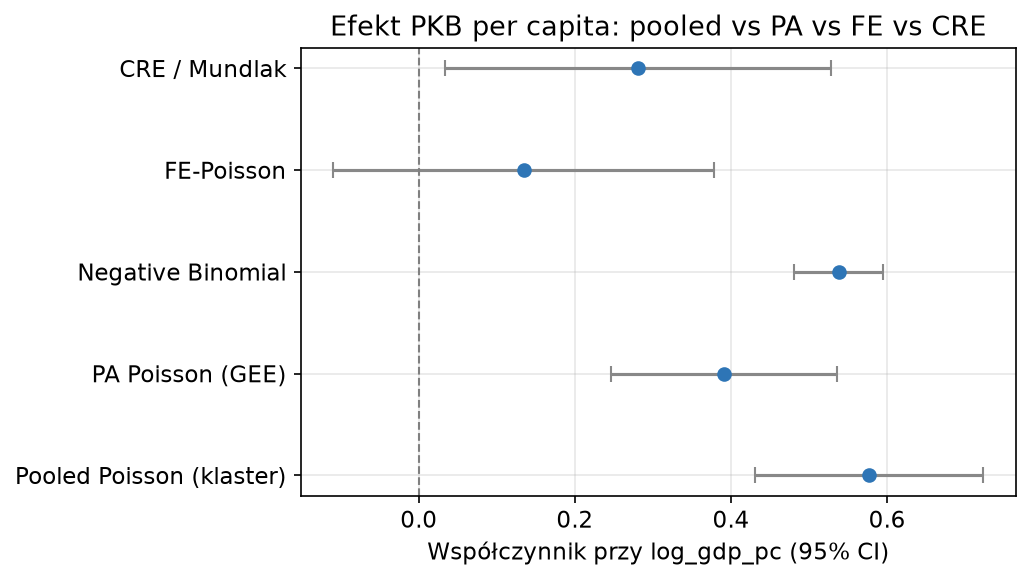

In [17]:
viz.plot_gdp_effect(comp);

### Wnioski- **Dyspersja** (4a): Pearson χ²/df = 6,06 przy 12 529 na 2 067 stopni swobody, czyli  czysty Poisson źle liczy błędy standardowe. Stąd klaster (4b), NegBin (4c) i ZIP (4g).- **Pooled/PA vs FE** (4b/4e vs 4d): współczynnik przy `log_gdp_pc` spada z 0,577  (pooled, klaster) przez 0,392 (PA) do 0,135 (FE) i w FE traci istotność (p = 0,28).  Efekt zamożności jest więc niemal w całości efektem **między** krajami: bogatsze kraje  zdobywają więcej medali, ale wzrost PKB per capita wewnątrz kraju w czasie nie  przekłada się wyraźnie na medale.- **Test Mundlaka** (4f): średnie `*_bar` łącznie istotne, więc efekt stały jest  skorelowany z regresorami i **FE jest właściwsze niż RE**. CRE pozwala mimo to  interpretować zmienne quasi-stałe, dając dla PKB wartość pośrednią (0,281).- **Populacja i gospodarz**: dodatnie i istotne we wszystkich specyfikacjach. W FE  elastyczność względem populacji rośnie do 1,26, a bycie gospodarzem podnosi oczekiwaną  liczbę medali o około połowę (IRR = exp(0,413) ≈ 1,51).- **Model rekomendowany**: FE-Poisson z odporną macierzą wariancji.

## 6. Tabele naukowe (eksport HTML)Tabele w stylu publikacyjnym: współczynnik z gwiazdkami istotności, błąd standardowy w nawiasie pod spodem, kolumna IRR jako efekt mnożnikowy, sekcja statystyk/diagnostyki i nota „Źródło”. Każda tabela jest zapisywana do pliku `.html` i wyświetlana inline.- **Tabela 2** — model główny (pooled Poisson + SE klastrowane po kraju)- **Tabela 3** — porównanie dopasowania (Poisson / NegBin / ZIP, AIC)- **Tabela 4** — FE-Poisson (efekty stałe kraju + igrzysk) + test Mundlaka- **Tabela 5** — efekt PKB per capita w różnych estymatorach- **Tabela 6** — zbiorcze zestawienie wszystkich modeli (pełne oszacowania wszystkich zmiennych)- **Tabela 7** — Zero-inflated Poisson (część liczebnościowa i inflacyjna)

In [18]:
# Wielkosci diagnostyczne wspolne dla tabel
fmt, stars = viz.fmt, viz.stars
chi2_p, df_p, disp = inference.dispersion_parts(pois)
mundlak_chi2, mundlak_p = inference.mundlak_test(cre, bars)
print(f'dyspersja={disp:.3f} | Mundlak chi2={mundlak_chi2:.2f} (p={mundlak_p:.4f})')

dyspersja=6.062 | Mundlak chi2=17.84 (p=0.0013)


In [19]:
# Tabela 2. Model glowny: pooled Poisson + SE klastrowane po kraju
stats2 = [
    ('Opóźniona zmienna zależna (medals_lag)', 'tak (kontrola)'),
    ('Efekty stałe kraju / igrzysk', 'nie (pooled)'),
    ('Błędy standardowe', 'klastrowane po kraju'),
    ('Liczba obserwacji (N)', int(pois_cl.nobs)),
    ('Liczba krajów', int(model_df['country_noc'].nunique())),
    ('Pseudo-R²', fmt(pois_cl.prsquared)),
    ('Pearson χ²/df', fmt(disp)),
]
note2 = ('W nawiasach błędy standardowe klastrowane na poziomie kraju. '
         'Istotność: *** p&lt;0,01, ** p&lt;0,05, * p&lt;0,1. '
         'IRR = exp(β); dla zmiennych w logarytmach β ≈ elastyczność.')
html2 = viz.reg_table_html(
    'Tabela 2. Model główny: pooled Poisson z SE klastrowanymi po kraju',
    model.TERMS, dict(pois_cl.params), dict(pois_cl.bse), dict(pois_cl.pvalues),
    stats2, note2)
viz.save_table(html2, 'tabela2_pooled_poisson.html');

Zapisano tabelę: tabela2_pooled_poisson.html


In [20]:
# Tabela 3. Porownanie dopasowania modeli liczebnosci (AIC)
rows3 = [
    ('<strong>Pooled Poisson</strong>', fmt(pois.llf), fmt(pois.aic),
     'χ²/df = ' + fmt(disp)),
    ('<strong>Negative Binomial (NB2)</strong>', fmt(negbin.llf), fmt(negbin.aic),
     'α = ' + fmt(float(negbin.params['alpha'])) + stars(negbin.pvalues['alpha'])),
]
if zip_res is not None:
    rows3.append(('<strong>Zero-inflated Poisson</strong>', fmt(zip_res.llf),
                  fmt(zip_res.aic), '—'))
note3 = ('Niższe AIC oznacza lepsze dopasowanie. Model ujemny dwumianowy i zero-inflated '
         'wyraźnie przewyższają czysty Poisson, co potwierdza nadmierną dyspersję i nadmiar '
         'zer. α — parametr dyspersji NB2.')
html3 = viz.simple_table_html(
    'Tabela 3. Porównanie dopasowania modeli liczebności',
    ['Model', 'Log-wiarygodność', 'AIC', 'Parametr'], rows3, note3)
viz.save_table(html3, 'tabela3_porownanie_dopasowania.html');

Zapisano tabelę: tabela3_porownanie_dopasowania.html


Model,Log-wiarygodność,AIC,Parametr
Pooled Poisson,"−6030,786","12071,571","χ²/df = 6,062"
Negative Binomial (NB2),"−3424,365","6860,730","α = 1,478***"
Zero-inflated Poisson,"−4693,261","9402,522",—


In [21]:
# Tabela 4. FE-Poisson (efekty stale kraju + igrzysk)
stats4 = [
    ('Efekty stałe kraju + igrzysk', 'tak'),
    ('Błędy standardowe', 'klastrowane po kraju (CRV1)'),
    ('Liczba obserwacji (N)', int(fepois._N)),
    ('Test Mundlaka (χ²)', f'{fmt(mundlak_chi2)} (p = {fmt(mundlak_p)})'),
]
note4 = ('W nawiasach błędy standardowe klastrowane na poziomie kraju (CRV1). '
         'Istotność: *** p&lt;0,01, ** p&lt;0,05, * p&lt;0,1. IRR = exp(β). '
         'Efekt log PKB per capita silnie maleje względem modelu pooled — zamożność '
         'działa głównie między krajami.')
html4 = viz.reg_table_html(
    'Tabela 4. FE-Poisson (efekty stałe kraju + igrzysk)',
    model.TERMS, dict(fepois.coef()), dict(fepois.se()), dict(fepois.pvalue()),
    stats4, note4)
viz.save_table(html4, 'tabela4_fe_poisson.html');

Zapisano tabelę: tabela4_fe_poisson.html


In [22]:
# Tabela 5. Efekt PKB per capita w roznych estymatorach
rows5 = [(f"<strong>{r['model']}</strong>", fmt(r['coef_log_gdp_pc']),
          f"({fmt(r['se'])})", fmt(r['IRR']), fmt(r['IRR_+10%PKB']))
         for _, r in comp.iterrows()]
note5 = ('Współczynnik przy log_gdp_pc; w nawiasach błędy standardowe. '
         'IRR = exp(β); IRR (+10% PKB) = efekt wzrostu PKB per capita o 10%. '
         'Spadek efektu od modelu pooled do FE pokazuje, że zamożność działa '
         'głównie między krajami.')
html5 = viz.simple_table_html(
    'Tabela 5. Efekt PKB per capita w różnych estymatorach panelowych',
    ['Estymator', 'Wsp. log_gdp_pc', 'Błąd std.', 'IRR', 'IRR (+10% PKB)'],
    rows5, note5)
viz.save_table(html5, 'tabela5_porownanie_pkb.html');

Zapisano tabelę: tabela5_porownanie_pkb.html


Estymator,Wsp. log_gdp_pc,Błąd std.,IRR,IRR (+10% PKB)
Pooled Poisson (klaster),"0,577","(0,074)","1,781","1,057"
PA Poisson (GEE),"0,392","(0,074)","1,479","1,038"
Negative Binomial,"0,538","(0,029)","1,712","1,053"
FE-Poisson,"0,135","(0,124)","1,144","1,013"
CRE / Mundlak,"0,281","(0,126)","1,325","1,027"


In [23]:
# Tabela 6. Zbiorcze zestawienie wszystkich modeli
models_all = [
    ('Pooled Poisson (klaster)', dict(pois_cl.params), dict(pois_cl.bse), dict(pois_cl.pvalues)),
    ('NegBin2', dict(negbin.params), dict(negbin.bse), dict(negbin.pvalues)),
    ('PA Poisson (GEE)', dict(ga.params), dict(ga.bse), dict(ga.pvalues)),
    ('FE-Poisson', dict(fepois.coef()), dict(fepois.se()), dict(fepois.pvalue())),
    ('CRE / Mundlak', dict(cre.params), dict(cre.bse), dict(cre.pvalues)),
]
row_keys_all = [
    ('log_gdp_pc', 'log PKB per capita'), ('log_pop', 'log populacji'),
    ('host', 'Gospodarz (host)'), ('medals_lag', 'medals_lag (kontrola)'),
    ('log_gdp_pc_bar', 'PKB pc — średnia (Mundlak)'),
    ('log_pop_bar', 'populacja — średnia (Mundlak)'),
    ('host_bar', 'host — średnia (Mundlak)'),
    ('medals_lag_bar', 'medals_lag — średnia (Mundlak)'),
]
_aic_zip = f'{cre.aic:.1f}'.replace('.', ',')
stat_rows_all = [
    ('Efekty stałe kraju + igrzysk', ['nie', 'nie', 'nie', 'tak', 'nie']),
    ('Średnie Mundlaka', ['nie', 'nie', 'nie', '—', 'tak']),
    ('Błędy standardowe', ['klaster', 'ML', 'robust (GEE)', 'CRV1', 'klaster']),
    ('Liczba obserwacji (N)', [int(pois_cl.nobs), int(negbin.nobs), int(ga.nobs),
                              int(fepois._N), int(cre.nobs)]),
    ('α (dyspersja, NB2)', ['—', fmt(float(negbin.params['alpha']))
                            + stars(negbin.pvalues['alpha']), '—', '—', '—']),
    ('AIC', [f'{pois.aic:.1f}'.replace('.', ','), f'{negbin.aic:.1f}'.replace('.', ','),
             '—', '—', _aic_zip]),
    ('Test Mundlaka (χ²)', ['—', '—', '—', '—',
                           f'{fmt(mundlak_chi2)} (p = {fmt(mundlak_p)})']),
]
note6 = ('W nawiasach błędy standardowe (rodzaj macierzy — patrz wiersz „Błędy standardowe”). '
         'Istotność: *** p&lt;0,01, ** p&lt;0,05, * p&lt;0,1. Współczynniki przy zmiennych '
         'w logarytmach ≈ elastyczności. Średnie Mundlaka identyfikowalne tylko w CRE; '
         'w FE-Poisson efekty kraju pochłaniają zmienne quasi-stałe. AIC porównywalne dla '
         'modeli o gęstości Poissona/NB. medals_lag pełni rolę zmiennej kontrolnej.')
html6 = viz.multi_table_html(
    'Tabela 6. Zestawienie wszystkich modeli — pełne oszacowania',
    models_all, row_keys_all, stat_rows_all, note6)
viz.save_table(html6, 'tabela6_zbiorcza.html');

Zapisano tabelę: tabela6_zbiorcza.html


Zmienna,Pooled Poisson (klaster),NegBin2,PA Poisson (GEE),FE-Poisson,CRE / Mundlak
log PKB per capita,"0,577***","0,538***","0,392***","0,135","0,281**"
,"(0,074)","(0,029)","(0,074)","(0,124)","(0,126)"
log populacji,"0,531***","0,500***","0,431***","1,261***","0,499***"
,"(0,060)","(0,025)","(0,042)","(0,314)","(0,159)"
Gospodarz (host),"0,435***","0,291","0,554***","0,413***","0,490***"
,"(0,073)","(0,342)","(0,059)","(0,083)","(0,073)"
medals_lag (kontrola),"0,011***","0,077***","0,007","0,008***","0,007*"
,"(0,004)","(0,005)","(0,005)","(0,003)","(0,004)"
PKB pc — średnia (Mundlak),—,—,—,—,"0,371***"
,,,,,"(0,128)"


In [24]:
# Tabela 7. Zero-inflated Poisson (czesc liczebnosciowa i inflacyjna)
if zip_res is None:
    print('ZIP nie zbiegl - tabela 7 pominieta.')
else:
    _P, _S, _PV = dict(zip_res.params), dict(zip_res.bse), dict(zip_res.pvalues)

    def _zrow(k, lab):
        return (f"<tr class='main'><td><strong>{lab}</strong></td>"
                f"<td>{fmt(_P[k])}{stars(_PV[k])}</td></tr>"
                f"<tr class='sub'><td></td><td>({fmt(_S[k])})</td></tr>")

    count_keys = [('log_gdp_pc', 'log PKB per capita'), ('log_pop', 'log populacji'),
                  ('host', 'Gospodarz (host)'), ('medals_lag', 'medals_lag (kontrola)'),
                  ('Intercept', 'Stała')]
    infl_keys = [('inflate_log_gdp_pc', 'log PKB per capita'),
                 ('inflate_log_pop', 'log populacji'), ('inflate_const', 'Stała')]

    body7 = '<tr><th>Zmienna</th><th>Współczynnik</th></tr>'
    body7 += ("<tr class='div'><td colspan='2'>Część liczebnościowa "
              "(Poisson, log-link)</td></tr>")
    body7 += ''.join(_zrow(k, l) for k, l in count_keys)
    body7 += ("<tr class='div'><td colspan='2'>Część inflacyjna "
              "(logit: P(zero strukturalne))</td></tr>")
    body7 += ''.join(_zrow(k, l) for k, l in infl_keys)
    _aic7 = f'{zip_res.aic:.1f}'.replace('.', ',')
    body7 += ("<tr class='div'><td colspan='2'>Statystyki</td></tr>"
              f"<tr><td>Liczba obserwacji (N)</td><td>{int(zip_res.nobs)}</td></tr>"
              f"<tr><td>AIC</td><td>{_aic7}</td></tr>")
    note7 = ('W nawiasach błędy standardowe. Istotność: *** p&lt;0,01, ** p&lt;0,05, '
             '* p&lt;0,1. Ujemne współczynniki w części inflacyjnej oznaczają, że wyższe '
             'PKB i populacja zmniejszają prawdopodobieństwo „zera strukturalnego” '
             '(kraju praktycznie bez szans na medal).')
    html7 = (viz.CSS + '<p><strong>Tabela 7. Zero-inflated Poisson '
             '(część liczebnościowa i inflacyjna)</strong></p>'
             "<table class='sci'>" + body7 + '</table>'
             f"<div class='note'>{viz.SOURCE_NOTE} {note7}</div>")
    viz.save_table(html7, 'tabela7_zip.html');

Zapisano tabelę: tabela7_zip.html
